# TP3 Small — Détection de fraude à l’ouverture d’un compte

**Question d’étude.** Sur un lot de demandes d’ouverture, quels dossiers examiner en priorité lorsque la fraude est rare et que chaque fausse alerte prend du temps à traiter ?

**Démarche.** Nous mesurons d’abord le déséquilibre et la qualité des données, puis nous comparons deux modèles de gradient boosting. Le mois 6 sert à choisir le modèle et le seuil. Le mois 7 sert à mesurer ce qu’aurait donné cette décision sur des demandes ultérieures.

| Partie | Question traitée |
|---|---|
| Data et EDA | Que contient une demande et quelle est la fréquence de la fraude ? |
| Prétraitement et transformation | Comment préparer les variables sans exploiter les mois futurs ? |
| Apprentissage | Que change la pondération des fraudes ? Quel seuil correspond au budget de revue ? |
| Évaluation | Combien de fraudes sont détectées, et combien de demandes légitimes déclenchent une alerte ? |
| Déploiement | Comment reproduire la même décision avec un nouveau CSV ? |

Le notebook Kaggle de départ présente une exploration de BAF et compare des modèles à arbres. Notre étude adapte cette démarche à une validation chronologique et à un budget de fausses alertes. [Notebook de Matthew McNulty](https://www.kaggle.com/code/matthewmcnulty/bank-account-fraud)

## Configuration
Imports et fonctions réutilisées pour l'apprentissage et l'inférence.

In [1]:
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
# Codes de données manquantes documentés dans la datasheet de Feedzai.
SENTINEL_COLUMNS = [
    "prev_address_months_count", "current_address_months_count",
    "intended_balcon_amount", "bank_months_count", "session_length_in_minutes",
    "device_distinct_emails_8w", "device_fraud_count",
]


def clean_features(frame):
    frame = frame.copy()
    for name in SENTINEL_COLUMNS:
        if name in frame:
            frame[name] = frame[name].mask(frame[name].eq(-1))
    return frame


def predict(bundle, rows):
    columns = bundle["columns"]
    missing = sorted(set(columns) - set(rows))
    if missing:
        raise ValueError(f"Colonnes d'entrée absentes : {', '.join(missing)}")
    features = clean_features(rows[columns])
    scores = bundle["model"].predict_proba(features)[:, 1]
    return pd.DataFrame({
        "score_fraude": scores,
        "alerte": (scores >= bundle["threshold"]).astype(int),
    })

TP = next((p for p in (Path.cwd(), Path.cwd() / "small", Path.cwd() / "TP3" / "small") if (p / "bank_fraud_dataset").is_dir()), None)
if TP is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis bigData/, TP3/ ou TP3/small/.")
ARTIFACTS = TP / "artefacts"
MODEL_NAME = "modele_fraude.joblib"

## 1. Data

### 1.1 Source et unité d’observation

On utilise `Base.csv`, la variante de référence de la suite Bank Account Fraud. Chaque ligne représente une demande synthétique d’ouverture de compte. La cible `fraud_bool` vaut 1 pour une fraude et 0 pour une demande légitime. `month` est un indice de 0 à 7 qui fixe l’ordre chronologique. [Projet et documentation Feedzai](https://github.com/feedzai/bank-account-fraud)

| Exemples de colonnes | Ce qu’elles décrivent |
|---|---|
| `customer_age`, `income` | Indicateurs décrivant le profil du demandeur |
| `payment_type`, `source`, `device_os` | Catégories de paiement, de canal et de système |
| `velocity_6h`, `session_length_in_minutes` | Indicateurs d’activité et de durée |
| `bank_months_count`, `prev_address_months_count` | Informations historiques, parfois indisponibles |
| `fraud_bool`, `month` | Étiquette et repère chronologique |

Le dossier GitHub contient `Base.csv.gz`, une copie compressée sans perte. pandas lit ce fichier directement lorsque `Base.csv` est absent.

In [2]:
DATA = TP / "bank_fraud_dataset" / "Base.csv"
if not DATA.is_file():
    DATA = DATA.with_suffix(".csv.gz")
if not DATA.is_file():
    raise FileNotFoundError("Placer Base.csv ou Base.csv.gz dans bank_fraud_dataset/.")

TARGET = "fraud_bool"
df = pd.read_csv(DATA)
assert set(df[TARGET].unique()) == {0, 1}
assert set(df["month"].unique()) == set(range(8))
print(f"{len(df):,} demandes • {df.shape[1]} colonnes • {DATA.stat().st_size / 1e6:.1f} Mo")
display(df[["month", "payment_type", "income", "session_length_in_minutes", TARGET]].head())
print(f"Mémoire pandas : {df.memory_usage(deep=True).sum() / 1e6:.0f} Mo")
display(df.dtypes.value_counts().rename_axis("Type pandas").to_frame("Colonnes"))

1,000,000 demandes • 32 colonnes • 85.7 Mo


,month,payment_type,income,session_length_in_minutes,fraud_bool
0,0,AA,0.3,16.224843,0
1,0,AD,0.8,3.363854,0
2,0,AB,0.8,22.730559,0
3,0,AB,0.6,15.215816,0
4,0,AA,0.9,3.743048,0


Mémoire pandas : 481 Mo


,Colonnes
Type pandas,
int64,18
float64,9
object,5


## 2. EDA — Analyse exploratoire

### 2.1 Fréquence de la fraude et évolution mensuelle

L’exploration utilise les mois 0 à 5, réservés à l’apprentissage. Lorsque la fraude représente environ 1 % des dossiers, prédire systématiquement « légitime » donne une exactitude proche de 99 %. Cette référence détecte zéro fraude. Nous suivrons donc la précision et le rappel de la classe fraude.

In [3]:
eda = df.loc[df["month"] <= 5]
monthly = eda.groupby("month")[TARGET].agg(demandes="size", fraudes="sum", taux="mean")
quality = pd.DataFrame({
    "NaN": eda.isna().sum(),
    "sentinelles -1": eda[SENTINEL_COLUMNS].eq(-1).sum().reindex(eda.columns, fill_value=0),
})
display(monthly.style.format({"taux": "{:.2%}"}))

prevalence = eda[TARGET].mean()
display(Markdown(
    f"Sur l’apprentissage, **{prevalence:.2%}** des demandes sont frauduleuses. "
    f"La règle « toujours légitime » atteindrait **{1 - prevalence:.2%} d’exactitude**."
))

,demandes,fraudes,taux
month,,,
0,132440,1500,1.13%
1,127620,1198,0.94%
2,136979,1198,0.87%
3,150936,1392,0.92%
4,127691,1452,1.14%
5,119323,1411,1.18%


Sur l’apprentissage, **1.03%** des demandes sont frauduleuses. La règle « toujours légitime » atteindrait **98.97% d’exactitude**.

### 2.2 Valeurs manquantes visibles et valeurs sentinelles

`isna()` compte les valeurs manquantes explicites. Pour les colonnes documentées par Feedzai, nous comptons aussi les codes `-1`. Les deux comptages mesurent des situations distinctes. Le graphique juxtapose leur volume par colonne et l’évolution mensuelle du taux de fraude.

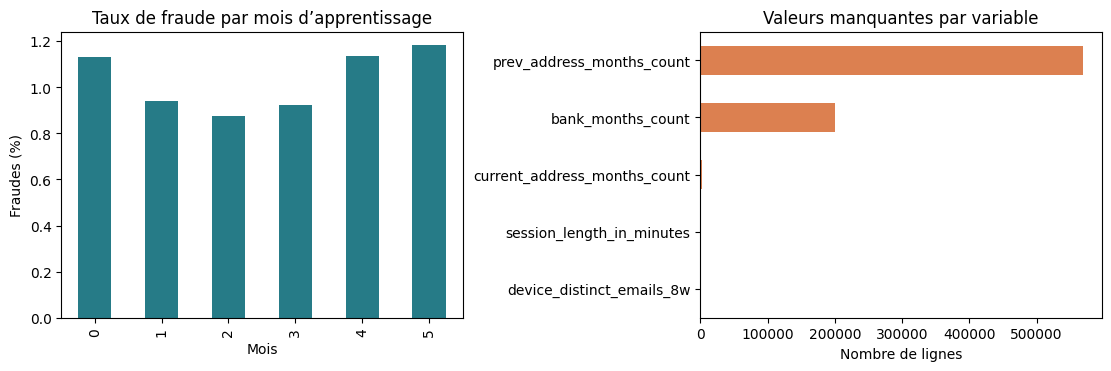

,NaN,sentinelles -1,part indisponible
prev_address_months_count,0,568423,71.50%
bank_months_count,0,199549,25.10%
current_address_months_count,0,3027,0.38%
session_length_in_minutes,0,1513,0.19%
device_distinct_emails_8w,0,309,0.04%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
(100 * monthly["taux"]).plot.bar(ax=axes[0], color="#267B87")
axes[0].set(title="Taux de fraude par mois d’apprentissage", ylabel="Fraudes (%)", xlabel="Mois")
quality.sum(axis=1).loc[lambda s: s.gt(0)].sort_values().plot.barh(ax=axes[1], color="#DC8050")
axes[1].set(title="Valeurs manquantes par variable", xlabel="Nombre de lignes")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "eda.png", dpi=120)
plt.show()
quality["part indisponible"] = quality.sum(axis=1) / len(eda)
missing_quality = quality.loc[quality["part indisponible"] > 0]
display(missing_quality.sort_values("part indisponible", ascending=False)
        .style.format({"part indisponible": "{:.2%}"}))

### 2.3 Une variable catégorielle et ses effectifs

On examine `payment_type` pour illustrer le lien entre une catégorie et la fréquence de la cible. Les effectifs donnent le contexte du taux. Un taux élevé sur un petit groupe repose sur moins d’observations. Cette comparaison brute décrit une association dans l’échantillon.

,demandes,fraudes,taux
payment_type,,,
AB,288182,2996,1.04%
AA,208920,1048,0.50%
AC,198579,3134,1.58%
AD,99060,972,0.98%
AE,248,1,0.40%


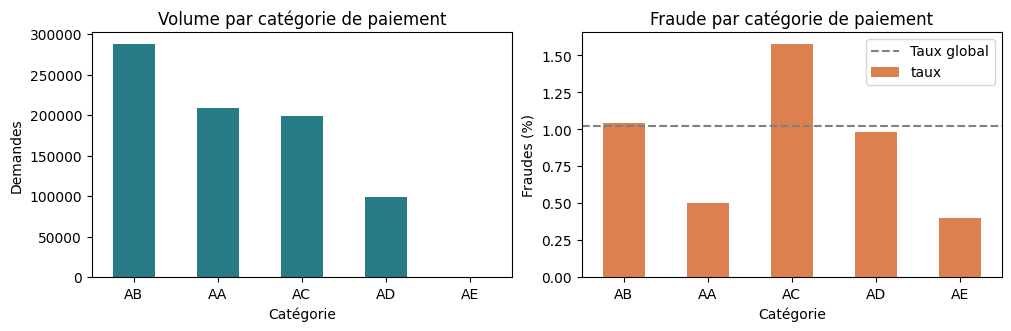

In [5]:
by_payment = (eda.groupby("payment_type", dropna=False)[TARGET]
              .agg(demandes="size", fraudes="sum", taux="mean")
              .sort_values("demandes", ascending=False))
display(by_payment.style.format({"taux": "{:.2%}"}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
by_payment["demandes"].plot.bar(ax=axes[0], color="#267B87", rot=0)
(100 * by_payment["taux"]).plot.bar(ax=axes[1], color="#DC8050", rot=0)
axes[0].set(title="Volume par catégorie de paiement", ylabel="Demandes", xlabel="Catégorie")
axes[1].set(title="Fraude par catégorie de paiement", ylabel="Fraudes (%)", xlabel="Catégorie")
axes[1].axhline(100 * prevalence, color="gray", ls="--", label="Taux global")
axes[1].legend()
plt.show()

## 3. Prétraitement
On retire les doublons exacts et on convertit `-1` en valeur manquante dans les seules colonnes où la documentation lui donne ce sens. On laisse les autres valeurs négatives intactes. Le mois sert à séparer les ensembles et ne fait pas partie des entrées du modèle.

| Ensemble | Mois | Rôle |
|---|---|---|
| Apprentissage | 0 à 5 | Ajuster les transformations et les modèles |
| Validation | 6 | Choisir la configuration et fixer le seuil |
| Test | 7 | Mesurer la performance sur un mois ultérieur |

### 3.1 Vérification des ensembles

L’ordre des mois reproduit une situation où les demandes futures arrivent après la mise au point du modèle. Un mélange aléatoire ferait intervenir les mêmes périodes pendant l’apprentissage et le test. Les effectifs permettent de vérifier que chaque partition contient des exemples des deux classes. Les taux des mois 6 et 7 apparaissent seulement après fixation du seuil, dans l’évaluation.

In [6]:
clean = df.drop_duplicates()
feature_names = [c for c in df.columns if c not in [TARGET, "month", "device_fraud_count"]]
partitions = {name: clean.loc[mask] for name, mask in {
    "train": clean["month"] < 6, "validation": clean["month"] == 6, "test": clean["month"] == 7,
}.items()}
x = {name: clean_features(part[feature_names]) for name, part in partitions.items()}
y = {name: part[TARGET] for name, part in partitions.items()}
assert all(values.nunique() == 2 for values in y.values())
print("Doublons retirés :", len(df) - len(clean))
print("Demandes par ensemble :", {name: len(part) for name, part in partitions.items()})
assert set(partitions["train"]["month"]) == set(range(6))
assert set(partitions["validation"]["month"]) == {6}
assert set(partitions["test"]["month"]) == {7}
assert TARGET not in feature_names and "month" not in feature_names
display(pd.DataFrame({
    "Mois": [", ".join(map(str, sorted(part["month"].unique()))) for part in partitions.values()],
    "Demandes": [len(part) for part in partitions.values()],
}, index=partitions.keys()))

Doublons retirés : 0
Demandes par ensemble : {'train': 794989, 'validation': 108168, 'test': 96843}


,Mois,Demandes
train,"0, 1, 2, 3, 4, 5",794989
validation,6,108168
test,7,96843


### 3.2 Exemple avant et après nettoyage

Pour les champs concernés, on remplace la sentinelle par `NaN`. Cela évite de traiter par exemple « ancienneté indisponible » comme une ancienneté d’un mois négatif. Le tableau montre les conversions sur les données d’apprentissage et les comptabilise par champ.

In [7]:
sentinels = [name for name in SENTINEL_COLUMNS if name in feature_names]
before_cleaning = partitions["train"][sentinels]
after_cleaning = x["train"][sentinels]
display(pd.DataFrame({
    "-1 avant": before_cleaning.eq(-1).sum(),
    "-1 après": after_cleaning.eq(-1).sum(),
    "NaN après": after_cleaning.isna().sum(),
}))

,-1 avant,-1 après,NaN après
prev_address_months_count,568423,0,568423
current_address_months_count,3027,0,3027
intended_balcon_amount,0,0,0
bank_months_count,199549,0,199549
session_length_in_minutes,1513,0,1513
device_distinct_emails_8w,309,0,309


## 4. Transformation
Un `ColumnTransformer` encode les catégories en indicatrices et accepte une catégorie inconnue au test. Le boosting gère les valeurs numériques manquantes. On retire aussi `device_fraud_count` : la variable est constante dans Base et n'apporte pas de signal. Le pipeline apprend l'encodage à l'entraînement.

### 4.1 Variables numériques et catégories

Les variables numériques conservent leur échelle. Le gradient boosting découpe ces variables en intervalles et traite les valeurs manquantes. L’encodage one-hot donne une colonne à chaque modalité connue pendant l’apprentissage. Une modalité rencontrée pour la première fois au test est encodée avec des zéros dans le bloc de cette variable. L’encodeur et le modèle appartiennent au même pipeline pour reproduire la transformation à l’inférence.

In [8]:
categorical = x["train"].select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric = [name for name in feature_names if name not in categorical]

def make_pipeline(weight):
    return Pipeline([
        ("encodage", ColumnTransformer([
            ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), categorical),
            ("numeriques", "passthrough", numeric),
        ])),
        ("modele", HistGradientBoostingClassifier(
            max_iter=120, max_leaf_nodes=31, learning_rate=0.1,
            class_weight=weight, early_stopping=False, random_state=42,
        )),
    ])

print("Variables catégorielles :", categorical)
print("Variables numériques :", len(numeric))
display(x["train"][categorical].nunique().rename_axis("Variable").to_frame("Modalités apprises"))

Variables catégorielles : ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
Variables numériques : 24


,Modalités apprises
Variable,
payment_type,5
employment_status,7
housing_status,7
source,2
device_os,5


## 5. ML — Apprentissage

### 5.1 Comparer deux modèles sur la validation

Les deux configurations utilisent la même architecture. La seconde donne davantage de poids à la classe rare pendant l’apprentissage. Nous utilisons l’**Average Precision** (AP) pour choisir entre les modèles sur le mois 6. L’AP résume le compromis précision–rappel en faisant varier le seuil. Pour un score constant, elle vaut la proportion de fraudes.

In [9]:
models, validation_ap = {}, {}
for name, weight in [("Boosting standard", None), ("Boosting pondéré", "balanced")]:
    model = make_pipeline(weight).fit(x["train"], y["train"])
    score = model.predict_proba(x["validation"])[:, 1]
    models[name] = model
    validation_ap[name] = average_precision_score(y["validation"], score)
display(pd.Series(validation_ap, name="AP · validation").sort_values(ascending=False).to_frame())

,AP · validation
Boosting pondéré,0.180302
Boosting standard,0.152935


### 5.2 Fixer un seuil en fonction du budget de fausses alertes

Le modèle fournit un score par dossier. Le seuil convertit ce score en décision de revue. Sur le mois 6, on retient le seuil qui maximise le rappel tout en signalant au plus **5 % des demandes légitimes**. Ce budget est une hypothèse du TP. On compare aussi d’autres budgets pour voir comment cette décision change le nombre de fraudes détectées.

Modèle : Boosting pondéré | Seuil : 0.80962 | Rappel validation : 51.86% | FPR : 4.99%


,Budget,Seuil,Faux positifs,Rappel
0,1%,0.9252,1.00%,23.72%
1,3%,0.8632,2.99%,43.10%
2,5%,0.8096,4.99%,51.86%
3,10%,0.6849,9.94%,67.79%


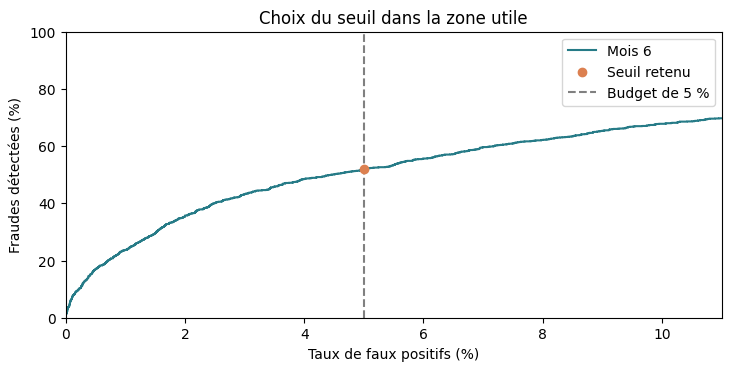

In [10]:
winner = max(validation_ap, key=validation_ap.get)
model = models[winner]
validation_scores = model.predict_proba(x["validation"])[:, 1]
fpr, tpr, thresholds = roc_curve(y["validation"], validation_scores, drop_intermediate=False)
allowed = np.flatnonzero(fpr <= 0.05)
i = allowed[np.argmax(tpr[allowed])]
threshold = float(thresholds[i])
print(f"Modèle : {winner} | Seuil : {threshold:.5f} | Rappel validation : {tpr[i]:.2%} | FPR : {fpr[i]:.2%}")
budgets = [0.01, 0.03, 0.05, 0.10]
scenarios = []
for budget in budgets:
    feasible = np.flatnonzero(fpr <= budget)
    point = feasible[np.argmax(tpr[feasible])]
    scenarios.append({
        "Budget": budget,
        "Seuil": thresholds[point],
        "Faux positifs": fpr[point],
        "Rappel": tpr[point],
    })
scenarios = pd.DataFrame(scenarios)
display(scenarios.style.format({
    "Budget": "{:.0%}", "Seuil": "{:.4f}", "Faux positifs": "{:.2%}", "Rappel": "{:.2%}",
}))
fig, ax = plt.subplots(figsize=(7.2, 3.6), layout="constrained")
ax.plot(100 * fpr, 100 * tpr, color="#267B87", label="Mois 6")
ax.scatter(100 * fpr[i], 100 * tpr[i], color="#DC8050", zorder=3, label="Seuil retenu")
ax.axvline(5, color="gray", ls="--", label="Budget de 5 %")
ax.set(xlim=(0, 11), ylim=(0, 100), xlabel="Taux de faux positifs (%)",
       ylabel="Fraudes détectées (%)", title="Choix du seuil dans la zone utile")
ax.legend()
plt.show()

### 5.3 Examiner les variables auxquelles le modèle est sensible

Sur 12 000 demandes tirées du mois 6 en conservant la proportion de fraudes, on mélange une variable à la fois. Une baisse d’AP indique que le modèle s’appuie sur cette information dans cet échantillon. Les barres montrent la moyenne de trois permutations et leur dispersion. Deux variables corrélées peuvent se remplacer, et ce calcul ne mesure pas un effet causal.

Dans l’exécution fournie, les deux plus fortes baisses d’AP apparaissent après permutation de `housing_status` (0,0301) et de `device_os` (0,0294). Leur écart est petit par rapport à la dispersion entre permutations, donc leur ordre reste incertain.

Le pipeline transforme 29 variables en 50 colonnes.


,Exemples de colonnes encodées
0,categories__payment_type_AA
1,categories__payment_type_AB
2,categories__payment_type_AC
3,categories__payment_type_AD
4,categories__payment_type_AE
5,categories__employment_status_CA
6,categories__employment_status_CB
7,categories__employment_status_CC


,Baisse d’AP,Écart-type
housing_status,0.0301,0.0016
device_os,0.0294,0.0038
has_other_cards,0.0196,0.0030
prev_address_months_count,0.0139,0.0006
income,0.0122,0.0004
keep_alive_session,0.0119,0.0020
email_is_free,0.0116,0.0041
name_email_similarity,0.0096,0.0016


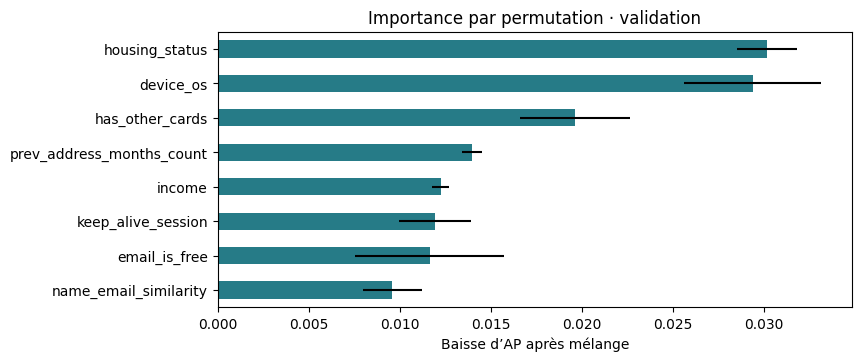

In [11]:
encoded_names = model.named_steps["encodage"].get_feature_names_out()
print(f"Le pipeline transforme {len(feature_names)} variables en {len(encoded_names)} colonnes.")
display(pd.DataFrame({"Exemples de colonnes encodées": encoded_names[:8]}))
x_sample, _, y_sample, _ = train_test_split(
    x["validation"], y["validation"], train_size=12_000, stratify=y["validation"], random_state=42,
)
importance = permutation_importance(
    model, x_sample, y_sample, scoring="average_precision", n_repeats=3, random_state=42,
)
ranking = pd.DataFrame({
    "Baisse d’AP": importance.importances_mean,
    "Écart-type": importance.importances_std,
}, index=feature_names).sort_values("Baisse d’AP", ascending=False)
display(ranking.head(8).round(4))
top = ranking.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
top["Baisse d’AP"].plot.barh(xerr=top["Écart-type"], ax=ax, color="#267B87")
ax.set(title="Importance par permutation · validation", xlabel="Baisse d’AP après mélange")
plt.show()

## 6. Évaluation
La référence naïve prédit toujours « légitime » ; son score constant donne une AP égale à la prévalence du test. On compare l'AP, l'AUC ROC et, au seuil fixé, la précision, le rappel, le F1 et le taux de faux positifs. La matrice de confusion traduit ces taux en demandes concrètes.

### 6.1 Résultats du mois 7

L’AP et l’AUC ROC évaluent le classement des dossiers. La précision, le rappel et le taux de faux positifs décrivent les décisions **au seuil choisi sur le mois 6**. La précision répond à « quelle part des alertes correspond à une fraude ? ». Le rappel répond à « quelle part des fraudes reçoit une alerte ? ». Le taux de faux positifs rapporte les fausses alertes au nombre de demandes légitimes.

,AP,AUC ROC,Précision,Rappel,F1,Taux faux positifs
Toujours légitime,0.0147,0.5000,0.0000,0.0000,0.0000,0.0000
Boosting pondéré,0.2163,0.8948,0.1615,0.5322,0.2478,0.0413


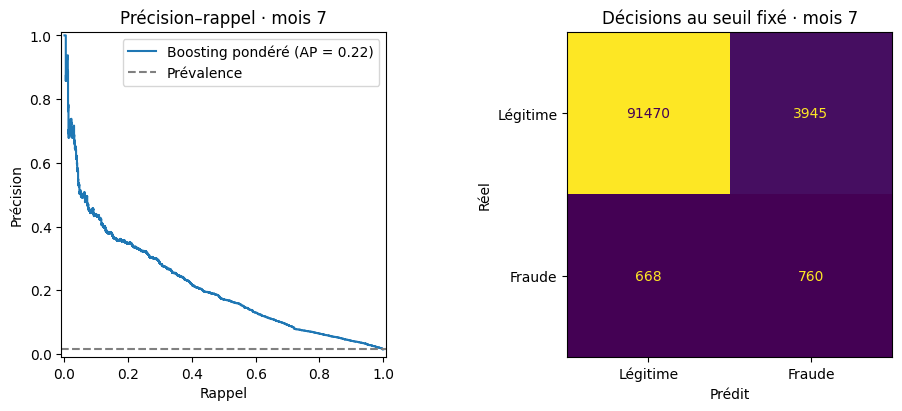

760 fraudes détectées sur 1,428 ; 3,945 demandes légitimes signalées.


In [12]:
y_test = y["test"]
test_scores = model.predict_proba(x["test"])[:, 1]
test_labels = (test_scores >= threshold).astype(int)
naive_scores = np.full(len(y_test), y["train"].mean())

def metrics(scores, decisions):
    tn, fp, fn, tp = confusion_matrix(y_test, decisions, labels=[0, 1]).ravel()
    return {
        "AP": average_precision_score(y_test, scores), "AUC ROC": roc_auc_score(y_test, scores),
        "Précision": precision_score(y_test, decisions, zero_division=0),
        "Rappel": recall_score(y_test, decisions), "F1": f1_score(y_test, decisions),
        "Taux faux positifs": fp / (fp + tn),
    }

results = pd.DataFrame({
    "Toujours légitime": metrics(naive_scores, np.zeros(len(y_test), dtype=int)),
    winner: metrics(test_scores, test_labels),
}).T
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
PrecisionRecallDisplay.from_predictions(y_test, test_scores, name=winner, ax=axes[0])
axes[0].axhline(y_test.mean(), color="gray", ls="--", label="Prévalence")
axes[0].legend()
axes[0].set(title="Précision–rappel · mois 7", xlabel="Rappel", ylabel="Précision")
ConfusionMatrixDisplay.from_predictions(
    y_test, test_labels, labels=[0, 1], display_labels=["Légitime", "Fraude"], ax=axes[1], colorbar=False,
)
axes[1].set(title="Décisions au seuil fixé · mois 7", xlabel="Prédit", ylabel="Réel")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "evaluation.png", dpi=120)
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, test_labels, labels=[0, 1]).ravel()
print(f"{tp:,} fraudes détectées sur {tp + fn:,} ; {fp:,} demandes légitimes signalées.")

### 6.2 Relier les métriques au travail de revue

Le tableau traduit les décisions du mois 7 en dossiers à traiter. On montre aussi, à titre de repère, ce qu’aurait donné un seuil de 0,50 appliqué aux mêmes scores. Les deux lignes sont évaluées après avoir figé le seuil principal.

Sur le mois 7, passer du seuil de 0,50 au seuil retenu ramène le volume de revue de **16 557 à 4 705 dossiers**. Ce choix évite **11 492 fausses alertes**, au prix de **360 fraudes détectées en moins**. Le seuil correspond donc à une décision sur le volume de revue.

In [13]:
outcomes = []
for name, cutoff in [("Seuil choisi sur le mois 6", threshold), ("Repère à 0,50", 0.5)]:
    labels = test_scores >= cutoff
    true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_test, labels, labels=[0, 1]).ravel()
    outcomes.append({
        "Décision": name, "Alertes": int(true_pos + false_pos), "Fraudes détectées": int(true_pos),
        "Fraudes manquées": int(false_neg), "Fausses alertes": int(false_pos),
        "Précision": true_pos / max(true_pos + false_pos, 1),
        "Taux faux positifs": false_pos / (false_pos + true_neg),
    })
display(pd.DataFrame(outcomes).set_index("Décision").style.format({
    "Précision": "{:.2%}", "Taux faux positifs": "{:.2%}",
}))
display(Markdown(
    f"Au seuil retenu, **{tp + fp:,} dossiers** seraient examinés, dont "
    f"**{tp:,} fraudes détectées** et **{fp:,} demandes légitimes**. "
    f"**{fn:,} fraudes** passent sous le seuil."
))

,Alertes,Fraudes détectées,Fraudes manquées,Fausses alertes,Précision,Taux faux positifs
Décision,,,,,,
Seuil choisi sur le mois 6,4705,760,668,3945,16.15%,4.13%
"Repère à 0,50",16557,1120,308,15437,6.76%,16.18%


Au seuil retenu, **4,705 dossiers** seraient examinés, dont **760 fraudes détectées** et **3,945 demandes légitimes**. **668 fraudes** passent sous le seuil.

### 6.3 Variation dans le temps et lecture par tranche d’âge

On compare la proportion de fraudes dans les trois ensembles et, à titre exploratoire, le rappel et le taux de faux positifs dans trois tranches d’âge sur le mois 7. Les différences observées peuvent refléter les effectifs, la composition des groupes ou la période. Les résultats sont descriptifs et portent sur des demandes synthétiques.

In [14]:
display(pd.DataFrame({
    "Demandes": {name: len(values) for name, values in y.items()},
    "Fraudes": {name: int(values.sum()) for name, values in y.items()},
    "Prévalence": {name: values.mean() for name, values in y.items()},
}).style.format({"Prévalence": "{:.2%}"}))

age_group = pd.cut(x["test"]["customer_age"], bins=[-np.inf, 34, 54, np.inf],
                   labels=["≤ 34", "35–54", "≥ 55"])
audit = pd.DataFrame({"Âge": age_group, "Fraude": y_test, "Alerte": test_labels.astype(bool)})
audit["Fraude détectée"] = audit["Alerte"] & audit["Fraude"].eq(1)
audit["Fausse alerte"] = audit["Alerte"] & audit["Fraude"].eq(0)
age_summary = audit.groupby("Âge", observed=True).agg(
    demandes=("Fraude", "size"), fraudes=("Fraude", "sum"),
    détectées=("Fraude détectée", "sum"), fausses_alertes=("Fausse alerte", "sum"),
)
age_summary["Rappel"] = age_summary["détectées"].div(age_summary["fraudes"].replace(0, np.nan))
legitimate = age_summary["demandes"] - age_summary["fraudes"]
age_summary["Taux faux positifs"] = age_summary["fausses_alertes"].div(legitimate.replace(0, np.nan))
display(age_summary.style.format({"Rappel": "{:.2%}", "Taux faux positifs": "{:.2%}"}))

,Demandes,Fraudes,Prévalence
train,794989,8151,1.03%
validation,108168,1450,1.34%
test,96843,1428,1.47%


,demandes,fraudes,détectées,fausses_alertes,Rappel,Taux faux positifs
Âge,,,,,,
≤ 34,56316,574,225,1354,39.20%,2.43%
35–54,37585,692,426,2207,61.56%,5.98%
≥ 55,2942,162,109,384,67.28%,13.81%


### 6.4 Calibration — Que représente un score de fraude ?

Le score sert à classer les demandes. Pour savoir s’il correspond aussi à une probabilité de fraude, on compare, sur le mois 7, le score moyen et le taux de fraude observé dans dix groupes de taille comparable. Une courbe proche de la diagonale indique que ces deux valeurs concordent. La pondération des classes pendant l’apprentissage peut éloigner les scores de la fréquence réelle.

Le **score de Brier** mesure l’écart quadratique moyen entre le score et la cible. Plus il est faible, mieux les valeurs prédites concordent avec les résultats observés. Il mesure à la fois la calibration et la capacité à distinguer les classes. La référence constante utilise la proportion de fraudes de l’apprentissage. [Courbes de calibration — scikit-learn](https://scikit-learn.org/1.6/auto_examples/calibration/plot_calibration_curve.html)

,Score moyen,Brier
Modèle,,
Prévalence de l’apprentissage,1.03%,0.01455
Boosting standard,1.21%,0.01342
Boosting pondéré,23.87%,0.11411


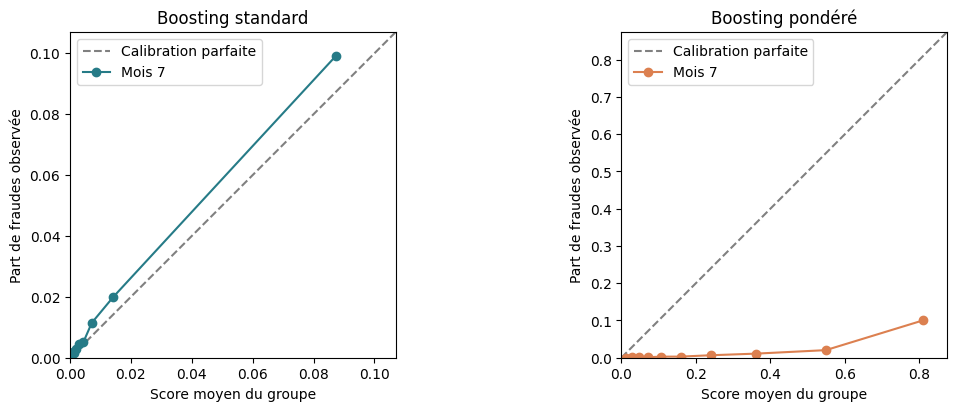

Le taux de fraude du mois 7 est de **1.47%**. Dans le groupe où le boosting pondéré donne les scores les plus élevés, le score moyen vaut **80.9%** et la part de fraudes observée est de **10.0%**. Ce décalage compte si on veut interpréter les scores comme des probabilités individuelles.

In [15]:
test_scores_by_model = {
    name: test_scores if name == winner else fitted.predict_proba(x["test"])[:, 1]
    for name, fitted in models.items()
}
score_sets = {"Prévalence de l’apprentissage": naive_scores, **test_scores_by_model}
calibration_summary = pd.DataFrame([
    {"Modèle": name, "Score moyen": scores.mean(), "Brier": brier_score_loss(y_test, scores)}
    for name, scores in score_sets.items()
]).set_index("Modèle")
display(calibration_summary.style.format({"Score moyen": "{:.2%}", "Brier": "{:.5f}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
colors = {"Boosting standard": "#267B87", "Boosting pondéré": "#DC8050"}
for ax, (name, scores) in zip(axes, test_scores_by_model.items()):
    observed, predicted = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    upper = min(1, 1.08 * max(predicted.max(), observed.max()))
    ax.plot([0, upper], [0, upper], ls="--", color="gray", label="Calibration parfaite")
    ax.plot(predicted, observed, marker="o", color=colors[name], label="Mois 7")
    ax.set(xlim=(0, upper), ylim=(0, upper), aspect="equal", title=name,
           xlabel="Score moyen du groupe", ylabel="Part de fraudes observée")
    ax.legend(loc="upper left")
plt.show()

observed, predicted = calibration_curve(
    y_test, test_scores_by_model["Boosting pondéré"], n_bins=10, strategy="quantile",
)
display(Markdown(
    f"Le taux de fraude du mois 7 est de **{y_test.mean():.2%}**. "
    f"Dans le groupe où le boosting pondéré donne les scores les plus élevés, "
    f"le score moyen vaut **{predicted[-1]:.1%}** et la part de fraudes observée est "
    f"de **{observed[-1]:.1%}**. Ce décalage compte si on veut interpréter "
    f"les scores comme des probabilités individuelles."
))

### 6.5 La pondération améliore-t-elle le classement sur le mois 7 ?

On calcule l’écart d’**Average Precision** entre le boosting pondéré et le boosting standard sur le même test. Pour mesurer l’incertitude, on réalise **500 tirages avec remise** parmi les demandes déjà présentes au mois 7. Les deux modèles sont comparés sur les mêmes lignes à chaque tirage. Ce bootstrap apparié ne réentraîne pas les modèles et ne crée aucun nouveau dossier.

Les quantiles 2,5 % et 97,5 % des écarts donnent un intervalle bootstrap à 95 %. Ce calcul traite les demandes comme indépendantes. L’intervalle décrit l’incertitude liée aux dossiers de ce mois pour les modèles déjà entraînés. Il ne mesure pas la variation entre mois.

,AP sur le mois 7
Boosting standard,0.1743
Boosting pondéré,0.2163
Écart pondéré − standard,0.0419


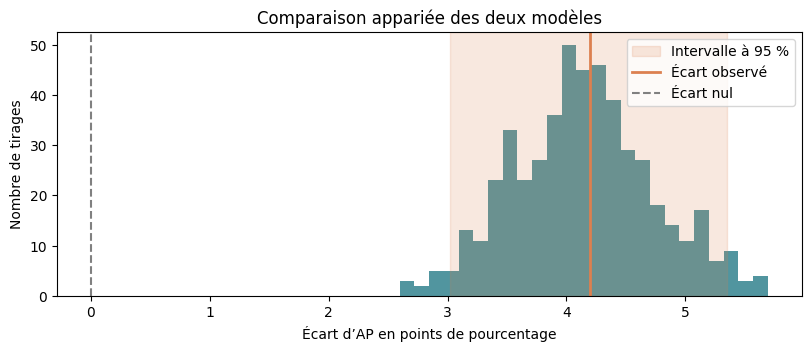

L’écart observé est de **+4.19 points d’AP**, avec un intervalle à 95 % de **[+3.02 ; +5.35] points**. Les tirages soutiennent un meilleur classement avec la pondération sur ce mois.

In [16]:
labels_test = y_test.to_numpy()
standard = test_scores_by_model["Boosting standard"]
weighted = test_scores_by_model["Boosting pondéré"]
ap_standard = average_precision_score(labels_test, standard)
ap_weighted = average_precision_score(labels_test, weighted)
gap = ap_weighted - ap_standard

rng = np.random.default_rng(42)
bootstrap_gaps = np.empty(500)
for i in range(len(bootstrap_gaps)):
    sampled = rng.integers(0, len(labels_test), size=len(labels_test))
    labels_sample = labels_test[sampled]
    bootstrap_gaps[i] = (
        average_precision_score(labels_sample, weighted[sampled])
        - average_precision_score(labels_sample, standard[sampled])
    )
lower, upper = np.quantile(bootstrap_gaps, [0.025, 0.975])
display(pd.DataFrame(
    {"AP sur le mois 7": [ap_standard, ap_weighted, gap]},
    index=["Boosting standard", "Boosting pondéré", "Écart pondéré − standard"],
).round(4))

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.hist(100 * bootstrap_gaps, bins=25, color="#267B87", alpha=0.8)
ax.axvspan(100 * lower, 100 * upper, color="#DC8050", alpha=0.18, label="Intervalle à 95 %")
ax.axvline(100 * gap, color="#DC8050", lw=2, label="Écart observé")
ax.axvline(0, color="gray", ls="--", label="Écart nul")
ax.set(xlabel="Écart d’AP en points de pourcentage", ylabel="Nombre de tirages",
       title="Comparaison appariée des deux modèles")
ax.legend()
plt.show()

if lower > 0:
    interpretation = "Les tirages soutiennent un meilleur classement avec la pondération sur ce mois."
elif upper < 0:
    interpretation = "Les tirages soutiennent un meilleur classement avec le modèle standard sur ce mois."
else:
    interpretation = "L’intervalle inclut zéro. Le test ne départage pas clairement les deux modèles."
display(Markdown(
    f"L’écart observé est de **{100 * gap:+.2f} points d’AP**, "
    f"avec un intervalle à 95 % de **[{100 * lower:+.2f} ; {100 * upper:+.2f}] points**. "
    + interpretation
))

## 7. Déploiement

### 7.1 Sauvegarder et recharger le pipeline

Le fichier Joblib contient l’encodeur, le modèle, la liste des colonnes et le seuil. Le JSON expose les informations utiles pour relire le résultat. On exporte cinq lignes d’exemple puis on vérifie que le modèle rechargé leur attribue les mêmes scores que pendant l’évaluation.

In [17]:
out = ARTIFACTS
out.mkdir(exist_ok=True)
bundle_path = out / MODEL_NAME
joblib.dump({"model": model, "columns": feature_names, "threshold": threshold}, bundle_path)
example = partitions["test"][feature_names].head(5)
example.to_csv(out / "exemple_entree.csv", index=False)
scored = predict(joblib.load(bundle_path), example)
np.testing.assert_allclose(scored["score_fraude"], test_scores[:5])
results.to_json(out / "metriques_test.json", orient="index", indent=2)
config = {
    "modele": winner,
    "fichier_modele": MODEL_NAME,
    "colonnes_entree": feature_names,
    "seuil_alerte": threshold,
    "fichier_metriques": "metriques_test.json",
}
(out / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

display(scored)

,score_fraude,alerte
0,0.178066,0
1,0.547056,0
2,0.032526,0
3,0.190908,0
4,0.028139,0


### Prédire avec le modèle sauvegardé
Pour prédire avec le modèle déjà exporté, exécuter **Configuration**, puis la cellule ci-dessous. Modifier `input_csv` pour utiliser un autre CSV comportant les mêmes colonnes. La cellule remplace le fichier `artefacts/predictions.csv`.

In [18]:
input_csv = ARTIFACTS / "exemple_entree.csv"
output_csv = ARTIFACTS / "predictions.csv"
if input_csv.resolve() == output_csv.resolve():
    raise ValueError("Choisir un fichier de sortie distinct du CSV d'entree.")
bundle = joblib.load(ARTIFACTS / MODEL_NAME)  # Artefact produit dans la cellule précédente.
predictions = predict(bundle, pd.read_csv(input_csv))
predictions.to_csv(output_csv, index=False)
display(predictions.head())

,score_fraude,alerte
0,0.178066,0
1,0.547056,0
2,0.032526,0
3,0.190908,0
4,0.028139,0


## Bilan

- **Données.** Le taux de fraude varie selon les mois, et les valeurs sentinelles modifient le bilan des données manquantes. La séparation chronologique permet de mesurer la performance sur une période ultérieure.
- **Modèle.** Dans l’exécution fournie, le boosting pondéré atteint une AP de **0,216** sur le mois 7, contre **0,0147** pour le score constant. Au seuil choisi sur le mois 6, il détecte **760 fraudes sur 1 428** et émet **3 945 fausses alertes**.
- **Interprétation.** Les métriques de classement et le seuil répondent à deux questions différentes. L’AP indique si le score place les fraudes en tête. Le seuil détermine le volume de dossiers à examiner et le nombre de fraudes captées.
- **Périmètre.** L’évaluation porte sur un mois de test synthétique. Pour étudier la stabilité dans le temps, il faudrait répéter l’évaluation sur plusieurs mois, avec des seuils fixés à l’avance et des effectifs suffisants par groupe.